In [5]:
import os
import glob
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image   

In [7]:
DATASET_DIR = Path(r"C:\Users\User\Desktop\road-damage-detection\datasets\RDD2022\RDD_SPLIT")

print("Dataset exists:", DATASET_DIR.exists())

Dataset exists: True


In [8]:
for path in DATASET_DIR.iterdir():
    print(path.name)

test
train
val


In [9]:
images = list(DATASET_DIR.rglob("*.jpg"))
annotations = list(DATASET_DIR.rglob("*.xml"))

print("Total images:", len(images))
print("Total XML annotations:", len(annotations))

Total images: 38385
Total XML annotations: 0


In [10]:
sizes = Counter()

for image_path in images:
    try:
        with Image.open(image_path) as img:
            sizes[img.size] += 1
    except Exception:
        pass

print(sizes)

Counter({(600, 600): 13016, (720, 720): 7706, (640, 640): 4805, (512, 512): 4378, (4040, 2035): 4342, (3643, 2041): 2896, (3650, 2044): 923, (1024, 1024): 147, (540, 540): 124, (1080, 1080): 48})


In [18]:
from collections import Counter

class_counts = Counter()

for label_file in TRAIN_LABELS.glob("*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) == 5:
                class_id = int(parts[0])
                class_counts[class_id] += 1

print("Class counts:", class_counts)

Class counts: Counter({0: 18201, 1: 8386, 3: 7554, 2: 7527, 4: 4628})


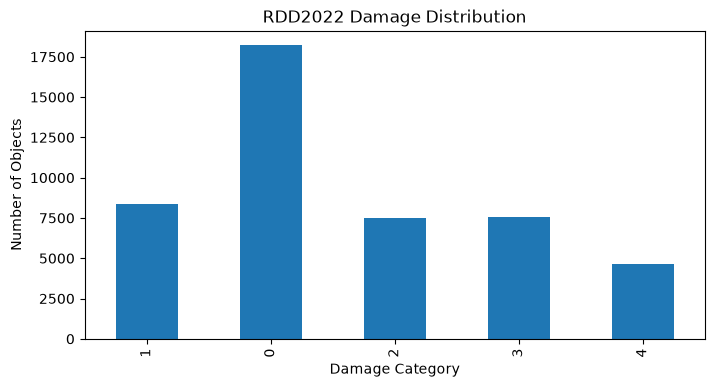

In [19]:
pd.Series(class_counts).plot(
    kind="bar",
    figsize=(8, 4),
    title="RDD2022 Damage Distribution"
)

plt.xlabel("Damage Category")
plt.ylabel("Number of Objects")
plt.show()

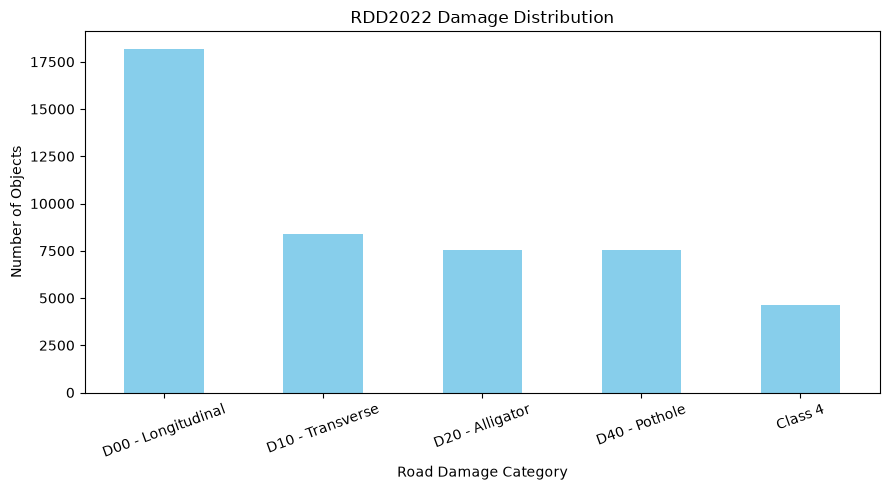

In [20]:
class_names = {
    0: "D00 - Longitudinal",
    1: "D10 - Transverse",
    2: "D20 - Alligator",
    3: "D40 - Pothole"
}

counts = pd.Series(class_counts).sort_index()
counts.index = [class_names.get(i, f"Class {i}") for i in counts.index]

counts.plot(
    kind="bar",
    figsize=(9, 5),
    color="skyblue",
    title="RDD2022 Damage Distribution"
)

plt.xlabel("Road Damage Category")
plt.ylabel("Number of Objects")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [21]:
from pathlib import Path
import xml.etree.ElementTree as ET

def inspect_annotation(xml_path):

    root = ET.parse(xml_path).getroot()

    filename = root.findtext("filename")
    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    objects = []

    for obj in root.findall("object"):
        box = obj.find("bndbox")

        objects.append({
            "class": obj.findtext("name"),
            "xmin": int(box.findtext("xmin")),
            "ymin": int(box.findtext("ymin")),
            "xmax": int(box.findtext("xmax")),
            "ymax": int(box.findtext("ymax"))
        })

    return {
        "filename": filename,
        "width": width,
        "height": height,
        "objects": objects
    } 